# **Assignment 11: Convolutional Neural Networks, Transfer Learning**

## Author: Mohammad Mehdi Zare, Mohammad Ali Olama

#Load Libraries

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(color_codes=True)
import pandas as pd
import numpy as np

import io
import os
import copy
import pdb
from keras.models import Sequential
from keras import callbacks
import keras
import tensorflow as tf
from sklearn.metrics import f1_score
from tensorflow.keras import initializers
from keras.regularizers import l2,l1,l1_l2
from keras.layers import Dense, Input, Dropout, Conv2D, AveragePooling2D, MaxPooling2D, Flatten, Reshape, Conv2DTranspose, LeakyReLU, BatchNormalization

%matplotlib inline
sns.set(color_codes=True)

In [2]:
# import TensorFlow
import tensorflow as tf

#Check the version of TensorFlow you are using
print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.17.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Diable warnings about max_itr not reached etc.!
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn

#Dataset

The Fashion MNIST dataset is a large freely available database of fashion images. It contains 70,000 28x28 grayscale images of fashion products from 10 categories from a dataset of Zalando article images, with 7,000 images per category. The training set consists of 60,000 images and the test set consists of 10,000 images.

Each training and test example is assigned to one of the following labels:

Label	Description
* 0	T-shirt/top
* 1	Trouser
* 2	Pullover
* 3	Dress
* 4	Coat
* 5	Sandal
* 6	Shirt
* 7	Sneaker
* 8	Bag
* 9	Ankle boot

In [51]:
fashion_mnist = keras.datasets.fashion_mnist
import tensorflow_datasets as tfds

(X_train,y_train),(X_test,y_test) = fashion_mnist.load_data()


print(f'size of training set: {X_train.shape}')
print(f'size of test set: {X_test.shape}')

size of training set: (60000, 28, 28)
size of test set: (10000, 28, 28)


to increase training speed, we stratify sample from this dataset and keep 20000 images from training data (2000 image for each class) and 1000 images for test set (100 image per class)

In [52]:
from sklearn.model_selection import train_test_split

# Function to perform stratified sampling
def stratified_sample(x, y, sample_size):

    # Perform stratified split using train_test_split
    _, x_sample, _, y_sample = train_test_split(
        x, y, test_size=sample_size, stratify=y, random_state=42
    )
    return x_sample, y_sample

# Stratified sampling on training set (10,000 samples)
X_train, y_train = stratified_sample(X_train, y_train, 20000)

# Stratified sampling on test set (1,000 samples)
X_test, y_test = stratified_sample(X_test, y_test, 1000)

# Check the distribution of classes in sampled datasets
print("Training set class distribution:", np.bincount(y_train))
print("Test set class distribution:", np.bincount(y_test))


Training set class distribution: [2000 2000 2000 2000 2000 2000 2000 2000 2000 2000]
Test set class distribution: [100 100 100 100 100 100 100 100 100 100]


Now let's take a look at sample images.

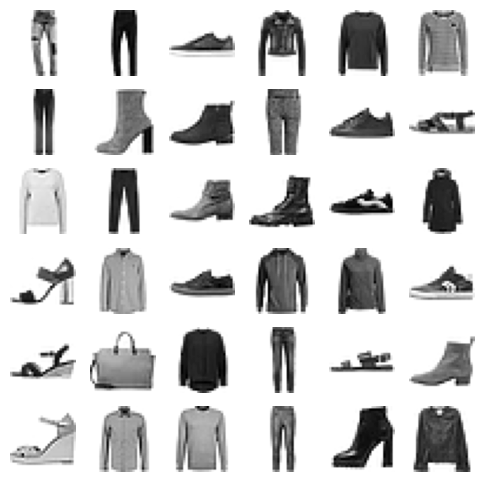

In [53]:
fig, ax = plt.subplots(nrows=6, ncols=6, figsize=(6,6))
itr = 0
for i in range(0,6):
  for j in range(0,6):
    itr += 1

    # convert to unsigned integers
    image = X_train[itr].reshape((28,28))
    # image = X_train[itr]

    # plot image
    ax[i,j].imshow(image,cmap='binary')
    ax[i,j].axis('off')

As you can see and as menstioned earlier, all classes have almost equal amount of samples.

Since we want to use Keras  API for this homework and the Keras models need to receive labels in the one-hot-encoding format, we do so in the cell below.

In [54]:
from sklearn.preprocessing import OneHotEncoder,LabelBinarizer
enc = LabelBinarizer()
y_train_enc = enc.fit_transform(y_train)
y_test_enc = enc.fit_transform(y_test)

In [55]:
y_train_enc.shape

(20000, 10)

In [56]:
y_train_enc[0]

array([0, 0, 0, 0, 0, 0, 1, 0, 0, 0])

Fashion Mnist is a well processed dataset and do not need any further cleaning.

#Utilities

The next three cells are some useful functions throughout the assignment.

In [10]:
def plot_history(history,plot_type: str='loss'):
  hist_df = pd.DataFrame(history.history)
  plt.figure(figsize=(20,8))
  colors = []
  columns_to_plot = []
  labels = []
  for col_name in hist_df.columns:

    # Define colors
    if 'val' in col_name:
      validation = True
      color_base = 'r'
      label_base = 'Validation'
    else:
      validation = False
      color_base = 'b'
      label_base = 'Training'

    if plot_type == 'loss':
      if 'loss' in col_name:
        labels.append(label_base)
        columns_to_plot.append(col_name)
        colors.append(color_base)
    else:
      if 'loss' in col_name:
        continue
      if 'recall' in col_name:
        color = color_base + '--'
        label = label_base + 'Recall'
      else:
        color = color_base
        label = label_base + 'Precision'

      labels.append(label)
      columns_to_plot.append(col_name)
      colors.append(color)



  for itr in range(0,len(columns_to_plot)):
    plt.plot(hist_df.loc[:, [columns_to_plot[itr]]], colors[itr], label=labels[itr],lw=4)

  plt.ylabel(plot_type)
  plt.xlabel('Epochs')
  plt.legend(loc="best")

  plt.show()

# Model

first we need to reshape the images from (28 , 28) to (28 , 28 , 1). It is an essential step for keras models.

In [57]:
# Reshape X_train to have a channel dimension (needed for Conv2D)
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)
X_train.shape

(20000, 28, 28, 1)

In [58]:
# import required libraries
from keras.layers import Dense, Input, Dropout, Conv2D, AveragePooling2D, MaxPooling2D, Flatten

In [59]:
# create a general function to create out model. we can create as many different models as we want.
# This function is adapted from course lab.
def create_model(hidden_layers: list=['Conv2D_3x3_10_1','MaxPooling2D_2x2_0','Conv2D_5x5_20_1','AveragePooling2D_2x2_1','Flatten','Dense_30'],
                 input_size=X_train.shape[1:], no_classes= y_train_enc.shape[1], activation_func: str='relu',
                 optimizer_name: str='adam',
                 learning_rate: float=0.01):



  model = Sequential()

  model.add(Input(shape=input_size))
  # Add hidden layers
  itr = 0
  for layer in hidden_layers:

      # Determine layer type
      layer_specs = layer.split('_')
      layer_type = layer_specs[0]
      eval_string = 'model.add('
      if layer_type == 'Dense':
        n_l = layer_specs[1]
        eval_string += 'Dense(%s,' %n_l
      elif layer_type == 'Flatten':
        eval_string += 'Flatten('
      elif layer_type == 'Conv2D':
        kernel_size = layer_specs[1]
        filters = layer_specs[2]
        stride = layer_specs[3]
        if not stride or stride == '0':
          stride = 'None'
        eval_string += 'Conv2D(kernel_size=(%s,%s),strides=%s,filters=%s,' %(kernel_size.split('x')[0],kernel_size.split('x')[1],stride,filters)
      elif 'pool' in layer_type.lower():
        pool_size = layer_specs[1]
        stride = layer_specs[2]
        if not stride or stride == '0':
          stride = 'None'
        eval_string += '%s(pool_size=(%s,%s),strides=%s,' %(layer_type,pool_size.split('x')[0],pool_size.split('x')[1],stride)

      if 'pool' not in layer_type.lower() and 'flatten' not in layer_type.lower():
        eval_string += 'activation="%s",' %activation_func

      eval_string += '))'

      # Add regularization
      if 1:
        eval(eval_string)
      else:
        pdb.set_trace()



      itr += 1

  # Add the last layer's activation layer

  model.add(Dense(no_classes, activation='softmax'))

  # Next, let's compile it
  if optimizer_name == 'sgd':
    opimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate)
  elif optimizer_name == 'RMSprop':
    opimizer = tf.keras.optimizers.RMSprop(learning_rate=learning_rate)
  elif optimizer_name == 'Adadelta':
    opimizer = tf.keras.optimizers.Adadelta(learning_rate=learning_rate)
  else:
    opimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
  model.compile(
        loss='categorical_crossentropy',
        optimizer=opimizer,
        metrics=['accuracy'],
        )

  return model

In [60]:
model = create_model(activation_func='sigmoid')
model.summary()

Model: "sequential_40"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_76 (Conv2D)                   │ (None, 26, 26, 10)          │             100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_47 (MaxPooling2D)      │ (None, 13, 13, 10)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_77 (Conv2D)                   │ (None, 9, 9, 20)            │           5,020 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_pooling2d_2                  │ (None, 8, 8, 20)            │               0 │
│ (AveragePooling2D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_40 (Flatten)                 │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_80 (Dense)                     │ (None, 30)                  │          38,430 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_81 (Dense)                     │ (None, 10)                  │             310 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 43,860 (171.33 KB)

 Trainable params: 43,860 (171.33 KB)

 Non-trainable params: 0 (0.00 B)

In [61]:
# train the model.
history = model.fit(X_train, y_train_enc,
                    batch_size = 256,
                    epochs = 50,
                    validation_split=0.2,
                    )

Epoch 1/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.1018 - loss: 2.3804 - val_accuracy: 0.0940 - val_loss: 2.3238
Epoch 2/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.1691 - loss: 2.1721 - val_accuracy: 0.2072 - val_loss: 1.8980
Epoch 3/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2917 - loss: 1.7824 - val_accuracy: 0.4757 - val_loss: 1.3784
Epoch 4/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6139 - loss: 1.2048 - val_accuracy: 0.7153 - val_loss: 0.8306
Epoch 5/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7367 - loss: 0.7757 - val_accuracy: 0.7505 - val_loss: 0.6769
Epoch 6/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7645 - loss: 0.6584 - val_accuracy: 0.7742 - val_loss: 0.6049
Epoch 7/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7849 - loss: 0.5784 - val_accuracy: 0.7890 - val_loss: 0.5576
Epoch 8/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8025 - loss: 0.5274 - val_accuracy: 0.8077 - val_loss

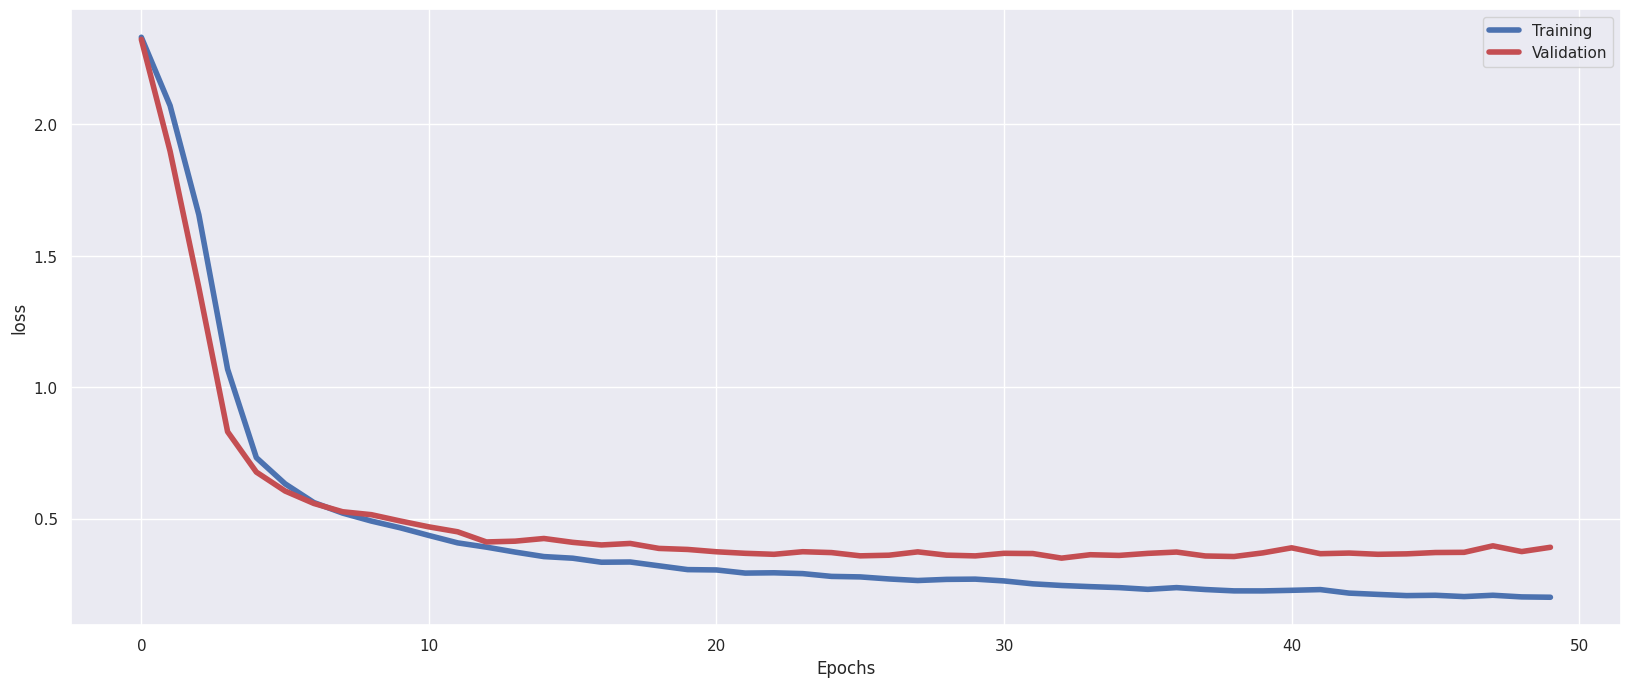

In [62]:
# plot the loss trend over epochs of training
plot_history(history,plot_type='loss')

In [63]:
# let's convert the output of model. Since it has softmax as the final layer, it outputs probabilities for each class.
# So we need to find the class with highest probability
def convert_predictions(predictions):
  output = np.argmax(predictions,axis=1)
  return output

predictions = model.predict(X_test)
print('Weighted F1-score is %.2f' %f1_score(y_test, convert_predictions(predictions), average='weighted'))

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Weighted F1-score is 0.88


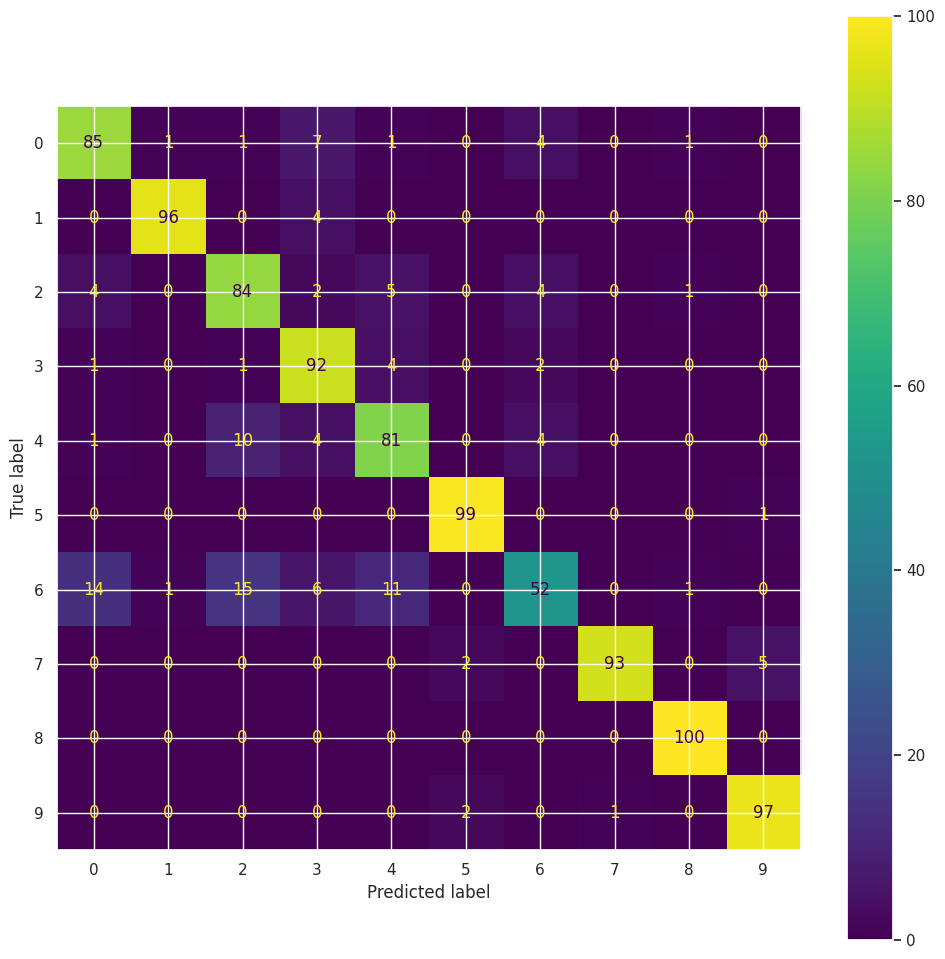

In [64]:
# confusion matrix of result
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay.from_predictions(y_test, convert_predictions(predictions),ax=ax)
plt.show()

# Fine tune the network

we will use the K-Fold technique for the following sections


In [19]:
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score

In [20]:
from sklearn.model_selection import KFold
import operator


import matplotlib.pyplot as plt

def plot_results_lr(results_lr , results_lr1):
  x_values = list(results_lr.keys())
  y_values = list(results_lr.values())
  y_values1 = list(results_lr1.values())
  plt.figure(figsize=(10, 6))
  plt.scatter(x_values, y_values)
  plt.scatter(x_values, y_values1 , color='orange')
  plt.plot(x_values, y_values, linestyle='-')
  plt.plot(x_values, y_values1, linestyle='-' , color='orange')
  plt.ylabel("Accuracy")
  plt.title("Accuracy trend")
  plt.legend(['Validation Set','Training Set'])
  plt.grid(True)
  plt.show()

def function(values_list):
  results_lr = {}
  results_lr_train = {}
  for index, conv in enumerate(values_list):
      print(conv)
      # Initialize KFold
      kf = KFold(n_splits=3, shuffle=True, random_state=42)

      accuracy_scores = []
      accuracy_scores_train = []
      for train_index, val_index in kf.split(X_train):
          X_fold_train, X_fold_val = X_train[train_index], X_train[val_index]
          y_fold_enc_train, y_fold_enc_val = y_train_enc[train_index], y_train_enc[val_index]
          y_fold_train, y_fold_val = y_train[train_index], y_train[val_index]
          model = create_model(hidden_layers =conv,  activation_func='sigmoid')

          history = model.fit(X_fold_train, y_fold_enc_train,
                      batch_size = 512,
                      epochs = 20,
                      verbose=0
                      )
          predictions = model.predict(X_fold_val)
          predicted_classes = convert_predictions(predictions)
          accuracy = accuracy_score(y_fold_val, predicted_classes)
          predictions_train = model.predict(X_fold_train)
          predicted_classes_train = convert_predictions(predictions_train)
          accuracy_train = accuracy_score(y_fold_train, predicted_classes_train)
          accuracy_scores.append(accuracy)
          accuracy_scores_train.append(accuracy_train)

      print("Accuracy scores for each fold:", accuracy_scores)
      print("Average accuracy:", np.mean(accuracy_scores))
      results_lr.update({index : np.mean(accuracy_scores)})
      results_lr_train.update({index : np.mean(accuracy_scores_train)})

  print(results_lr)
  best_lr = max(results_lr.items(), key=operator.itemgetter(1))
  print(f"The best setting is {values_list[best_lr[0]]} with an accuracy of {best_lr[1]}")
  plot_results_lr(results_lr, results_lr_train)

## Tuning the kernel size (i.e. the size of the receptive field) for convolutional layers

['Conv2D_3x3_10_1', 'MaxPooling2D_2x2_0', 'Conv2D_3x3_20_1', 'MaxPooling2D_2x2_0', 'Flatten', 'Dense_30']
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Accuracy scores for each fold: [0.856007199640018, 0.8491075446227688, 0.8456345634563457]
Average accuracy: 0.8502497692397109
['Conv2D_5x5_10_1', 'MaxPooling2D_2x2_0', 'Conv2D_5x5_20_1', 'MaxPooling2D_2x2_0', 'Flatten', 'Dense_30']
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Accuracy scores for each fold: [0.8402579871006449, 0.8524073796310184, 0.858985898589859]
Average accuracy: 0.8505504217738408
['Conv2D_7x7_10_1', 'MaxPooling2D_2x2_0'

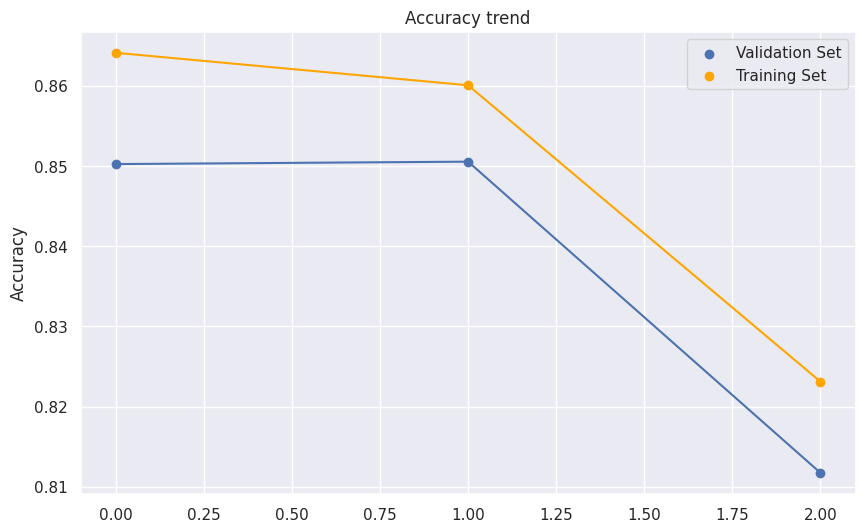

In [21]:
# Kernel size of 3
values_list = [['Conv2D_3x3_10_1','MaxPooling2D_2x2_0','Conv2D_3x3_20_1','MaxPooling2D_2x2_0','Flatten','Dense_30']]


# Kernel size of 5
values_list += [['Conv2D_5x5_10_1','MaxPooling2D_2x2_0','Conv2D_5x5_20_1','MaxPooling2D_2x2_0','Flatten','Dense_30']]

# Kernel size of 7
values_list += [['Conv2D_7x7_10_1','MaxPooling2D_2x2_0','Conv2D_7x7_20_1','MaxPooling2D_2x2_0','Flatten','Dense_30']]

function(values_list)

## Tuning the stride for convolutional layers

['Conv2D_3x3_10_1', 'MaxPooling2D_2x2_0', 'Conv2D_3x3_20_1', 'Flatten', 'Dense_30']
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Accuracy scores for each fold: [0.09569521523923803, 0.7375131243437828, 0.1041104110411041]
Average accuracy: 0.31243958354137497
['Conv2D_3x3_10_2', 'MaxPooling2D_2x2_0', 'Conv2D_3x3_20_2', 'Flatten', 'Dense_30']
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Accuracy scores for each fold: [0.80005999700015, 0.807709614519274, 0.7904290429042904]
Average accuracy: 0.7993995514745714
['Conv2D_3x3_10_3', 'MaxPooling2D_2x2_0', 'Conv2D_3x3_20_3', 'Flatten', 'Dense_30']

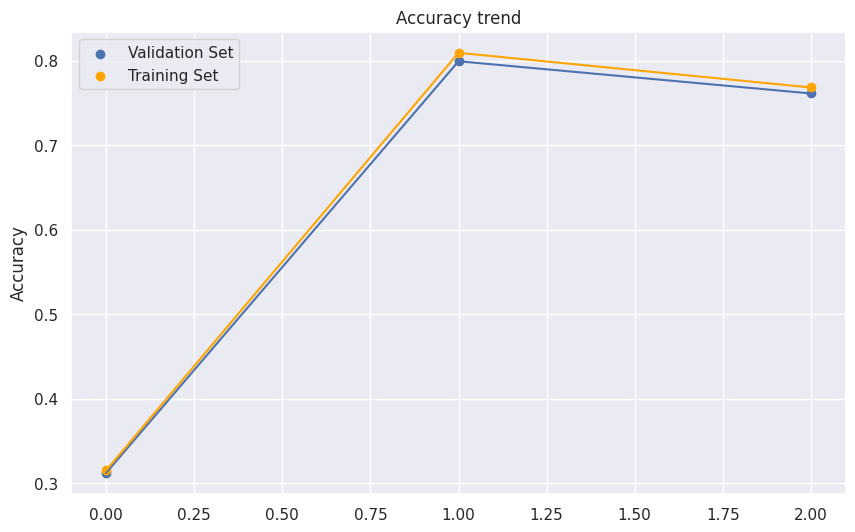

In [22]:
# Stride 1
values_list = [['Conv2D_3x3_10_1','MaxPooling2D_2x2_0','Conv2D_3x3_20_1','Flatten','Dense_30']]

# Stride 2
values_list += [['Conv2D_3x3_10_2','MaxPooling2D_2x2_0','Conv2D_3x3_20_2','Flatten','Dense_30']]

# Stride 3
values_list += [['Conv2D_3x3_10_3','MaxPooling2D_2x2_0','Conv2D_3x3_20_3','Flatten','Dense_30']]

function(values_list)

## Tuning the pooling size (i.e. the size of the receptive field) for pooling layers

['Conv2D_3x3_10_1', 'MaxPooling2D_2x2_0', 'Conv2D_3x3_20_1', 'Flatten', 'Dense_30']
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Accuracy scores for each fold: [0.10049497525123743, 0.09974501274936254, 0.6233123312331234]
Average accuracy: 0.27451743974457443
['Conv2D_3x3_10_1', 'MaxPooling2D_3x3_0', 'Conv2D_3x3_20_1', 'Flatten', 'Dense_30']
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Accuracy scores for each fold: [0.8440077996100195, 0.8470076496175192, 0.8472847284728473]
Average accuracy: 0.846100059233462
['Conv2D_3x3_10_1', 'MaxPooling2D_4x4_0', 'Conv2D_3x3_20_1', 'Flatten', 'Dense_3

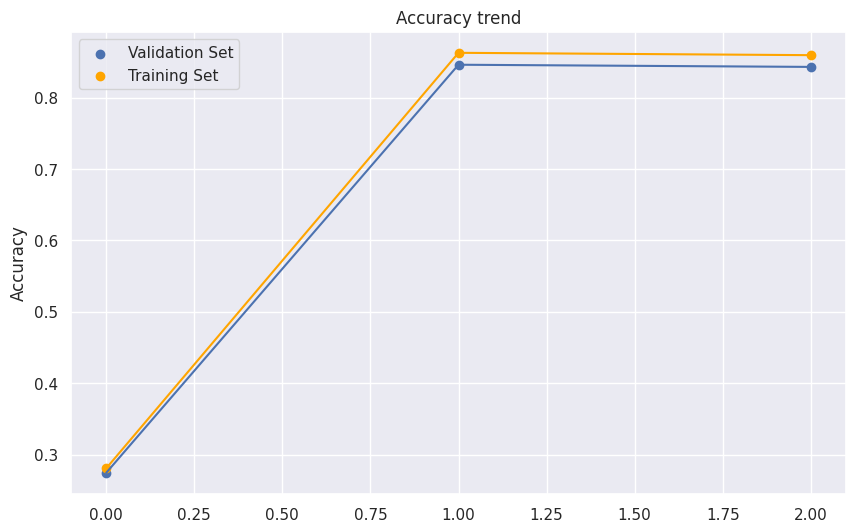

In [23]:
# pool size of 2
values_list = [['Conv2D_3x3_10_1','MaxPooling2D_2x2_0','Conv2D_3x3_20_1','Flatten','Dense_30']]


# pool size of 3
values_list += [['Conv2D_3x3_10_1','MaxPooling2D_3x3_0','Conv2D_3x3_20_1','Flatten','Dense_30']]

# pool size of 4
values_list += [['Conv2D_3x3_10_1','MaxPooling2D_4x4_0','Conv2D_3x3_20_1','Flatten','Dense_30']]

function(values_list)

## Tuning the stride for pooling layers

['Conv2D_3x3_10_1', 'MaxPooling2D_3x3_0', 'Conv2D_3x3_10_1', 'Flatten', 'Dense_30']
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Accuracy scores for each fold: [0.8359082045897706, 0.8582570871456427, 0.8370837083708371]
Average accuracy: 0.8437496667020835
['Conv2D_3x3_10_1', 'MaxPooling2D_3x3_1', 'Conv2D_3x3_10_1', 'Flatten', 'Dense_30']
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Accuracy scores for each fold: [0.10094495275236239, 0.09494525273736314, 0.10006000600060005]
Average accuracy: 0.0986500704967752
['Conv2D_3x3_10_1', 'MaxPooling2D_3x3_2', 'Conv2D_3x3_10_1', 'Flatten', 'Dense_

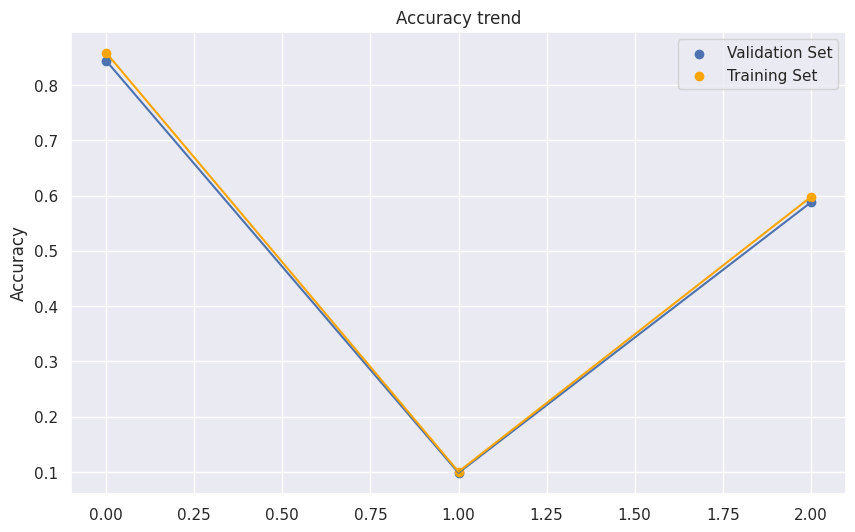

In [24]:
# stride pool size of 0
values_list = [['Conv2D_3x3_10_1','MaxPooling2D_3x3_0','Conv2D_3x3_10_1','Flatten','Dense_30']]


# stride pool size of 1
values_list += [['Conv2D_3x3_10_1','MaxPooling2D_3x3_1','Conv2D_3x3_10_1','Flatten','Dense_30']]

# stride pool size of 2
values_list += [['Conv2D_3x3_10_1','MaxPooling2D_3x3_2','Conv2D_3x3_10_1','Flatten','Dense_30']]

function(values_list)

# data augmentation

In [25]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [26]:
def plot_generated_images(image_generator,no_rows: int=6,no_columns: int=6):
  fig, ax = plt.subplots(nrows=no_rows, ncols=no_rows, figsize=(no_rows,no_columns))
  itr = 0
  for i in range(0,no_rows):
    for j in range(0,no_columns):

      batch = next(image_generator)
      # convert to unsigned integers for viewing
      image = batch[0].astype('uint8')

      # plot image
      ax[i,j].imshow(image , cmap='gray')
      ax[i,j].axis('off')

plt.show()

# Load an image
x = X_train[5,:,:]
x = 255*x.reshape((1,) + x.shape)
x.shape

(1, 28, 28, 1)

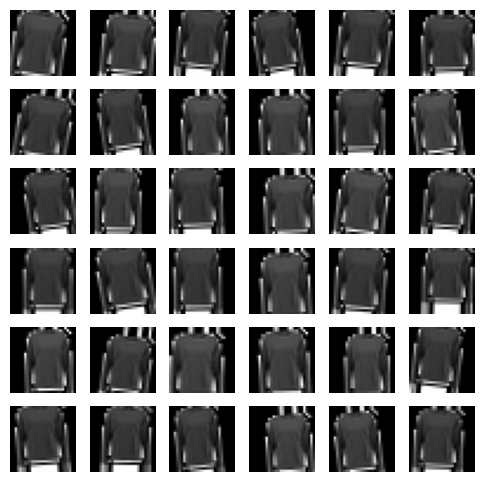

In [69]:
train_datagen = ImageDataGenerator(
        rotation_range=10,
        width_shift_range=0.1,
        height_shift_range=0.1,
        zoom_range=0.1,
        fill_mode='nearest',
        validation_split=0.2
        )
image_generator = train_datagen.flow(x, batch_size=1)
plot_generated_images(image_generator)



In [70]:
# Create training and validation set datasets with generator
train_iterator = train_datagen.flow(X_train, y_train_enc,subset='training',batch_size=256)
val_iterator = train_datagen.flow(X_train, y_train_enc,subset='validation',batch_size=256)

In [71]:
# create a new default model and fit
model = create_model(activation_func='sigmoid')
history = model.fit(
      train_iterator,
      validation_data=val_iterator,
      verbose=2,
      epochs=30,
)

Epoch 1/30
63/63 - 10s - 159ms/step - accuracy: 0.3101 - loss: 2.0935 - val_accuracy: 0.4712 - val_loss: 1.7864
Epoch 2/30
63/63 - 5s - 85ms/step - accuracy: 0.4597 - loss: 1.6446 - val_accuracy: 0.4750 - val_loss: 1.4962
Epoch 3/30
63/63 - 6s - 99ms/step - accuracy: 0.4857 - loss: 1.4230 - val_accuracy: 0.5000 - val_loss: 1.3391
Epoch 4/30
63/63 - 5s - 85ms/step - accuracy: 0.5041 - loss: 1.2962 - val_accuracy: 0.5023 - val_loss: 1.2785
Epoch 5/30
63/63 - 7s - 104ms/step - accuracy: 0.5163 - loss: 1.2253 - val_accuracy: 0.5340 - val_loss: 1.1642
Epoch 6/30
63/63 - 5s - 81ms/step - accuracy: 0.5253 - loss: 1.1758 - val_accuracy: 0.5167 - val_loss: 1.1084
Epoch 7/30
63/63 - 6s - 101ms/step - accuracy: 0.5316 - loss: 1.1399 - val_accuracy: 0.5210 - val_loss: 1.1111
Epoch 8/30
63/63 - 5s - 82ms/step - accuracy: 0.5480 - loss: 1.0985 - val_accuracy: 0.5493 - val_loss: 1.0514
Epoch 9/30
63/63 - 11s - 172ms/step - accuracy: 0.5558 - loss: 1.0626 - val_accuracy: 0.5580 - val_loss: 1.0354
Epoc

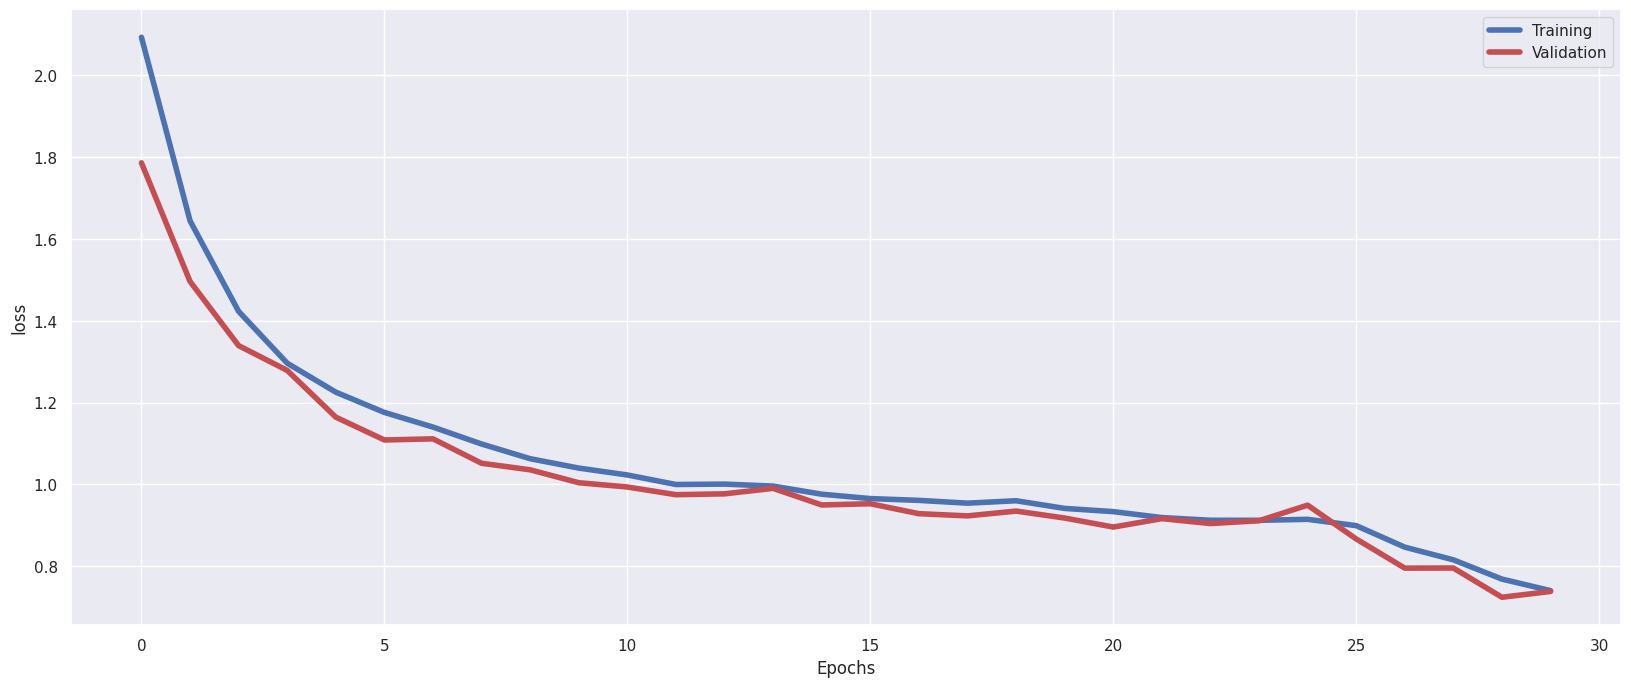

In [72]:
plot_history(history,plot_type='loss')

In [73]:
predictions = model.predict(X_test)
print('Weighted F1-score is %.2f' %f1_score(y_test, convert_predictions(predictions), average='weighted'))

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Weighted F1-score is 0.66


# Transfer Learning

For this part we change our dataset. since our previous dataset is grayscale but we need somehow a colorful image dataset! So we will be using the following dataset:

In [32]:
import tensorflow_datasets as tfds
import tensorflow as tf
import numpy as np
import keras

# Load the Rock, Paper, Scissors dataset from TensorFlow Datasets
(ds_train, ds_test), ds_info = tfds.load(
    'tf_flowers',
    split=['train[:85%]', 'train[85%:]'],  # Split 'train' into train and validation
    shuffle_files=True,
    as_supervised=True,  # This will return (image, label) pairs
    with_info=True
)

# Function to resize images and convert to NumPy arrays
def preprocess_image(image, label):
    # Resize the image to 100 * 100 for less computional cost and memory
    resized_image = tf.image.resize(image, (100, 100))
    # Convert the image to float32 and normalize pixel values to [0, 1]
    resized_image = tf.cast(resized_image, tf.float32) / 255.0
    return resized_image, label

# Apply the preprocessing function to the dataset
ds_train = ds_train.map(preprocess_image)
ds_test = ds_test.map(preprocess_image)

# Convert the TensorFlow Datasets to NumPy arrays
def to_numpy(ds):
    images = []
    labels = []
    for image, label in ds:
        images.append(image.numpy())
        labels.append(label.numpy())
    return np.array(images), np.array(labels)

X_train, y_train = to_numpy(ds_train)
X_test, y_test = to_numpy(ds_test)

print(f'size of training set: {X_train.shape}')
print(f'size of test set: {X_test.shape}')

Dl Completed...:   0%|          | 0/5 [00:00<?, ? file/s]

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
size of training set: (3120, 100, 100, 3)
size of test set: (550, 100, 100, 3)


In [33]:
# encode labels
enc = LabelBinarizer()
y_train_enc = enc.fit_transform(y_train)
y_test_enc = enc.fit_transform(y_test)

In [34]:
# create a function to append some layers at the end of base model.
def create_transfer_model(base_model,learning_rate=0.001,learning_rate_decay=0.9,no_classes=y_train_enc.shape[1]):
  model = Sequential()
  model.add(base_model)           #Adds the base model
  model.add(Flatten())
  model.add(Dense(128,activation=('relu')))
  model.add(Dropout(.2))
  model.add(Dense(no_classes,activation=('softmax')))

  model.compile(
          loss='categorical_crossentropy',
          optimizer= tf.keras.optimizers.Adam(learning_rate=learning_rate,beta_1=learning_rate_decay),
          metrics=['accuracy'],
          )
  return model



## VGG19

In [35]:
from tensorflow.keras.applications import VGG19

base_model = VGG19(
    include_top=False,    # We do not include the top, because we just need the feature extraction layers
    weights='imagenet',
    input_shape=X_train.shape[1:],
    classes=y_train_enc.shape[1])

# We make the weight non-trainable to reduce the number of weights in the network
for layer in base_model.layers:
    layer.trainable = False

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [36]:
model = create_transfer_model(base_model)
model.summary()

Model: "sequential_37"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)                   │ (None, 3, 3, 512)           │      20,024,384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_37 (Flatten)                 │ (None, 4608)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_74 (Dense)                     │ (None, 128)                 │         589,952 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_75 (Dense)                     │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 20,614,981 (78.64 MB)

 Trainable params: 590,597 (2.25 MB)

 Non-trainable params: 20,024,384 (76.39 MB)

In [37]:
history = model.fit(
      X_train, y_train_enc,
      verbose=1,
      epochs=20,
)

Epoch 1/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 13s 72ms/step - accuracy: 0.5131 - loss: 1.3216
Epoch 2/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.7356 - loss: 0.7263
Epoch 3/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.7959 - loss: 0.5847
Epoch 4/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.8222 - loss: 0.4806
Epoch 5/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.8388 - loss: 0.4495
Epoch 6/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.8691 - loss: 0.3755
Epoch 7/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.8931 - loss: 0.3134
Epoch 8/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9075 - loss: 0.2712
Epoch 9/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.9243 - loss: 0.2430
Epoch 10/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.9326 - loss: 0.2082
Epoch 11/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.9411 - loss: 0.1751
Epoch 12/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy

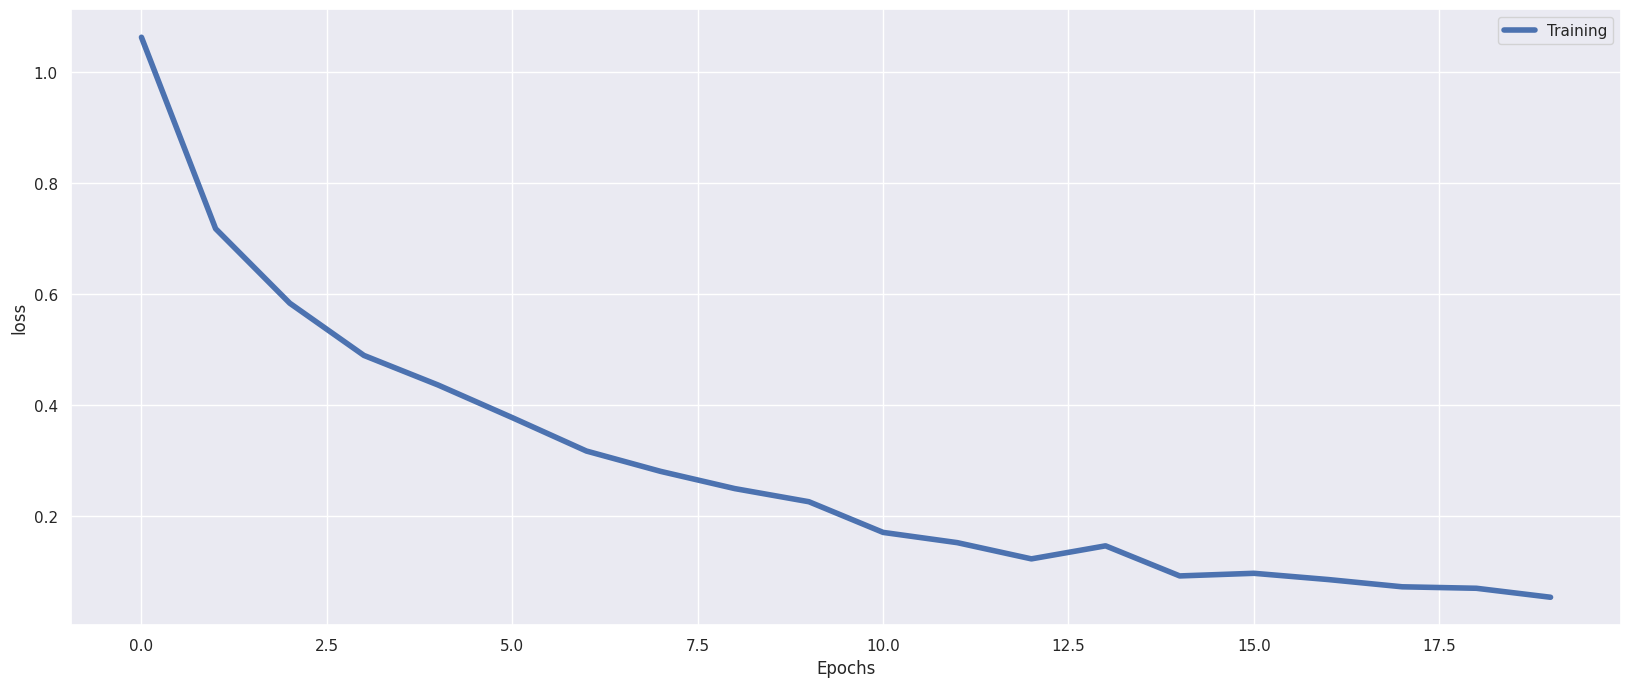

In [38]:
plot_history(history,plot_type='loss')

18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 166ms/step
Weighted F1-score is 0.76


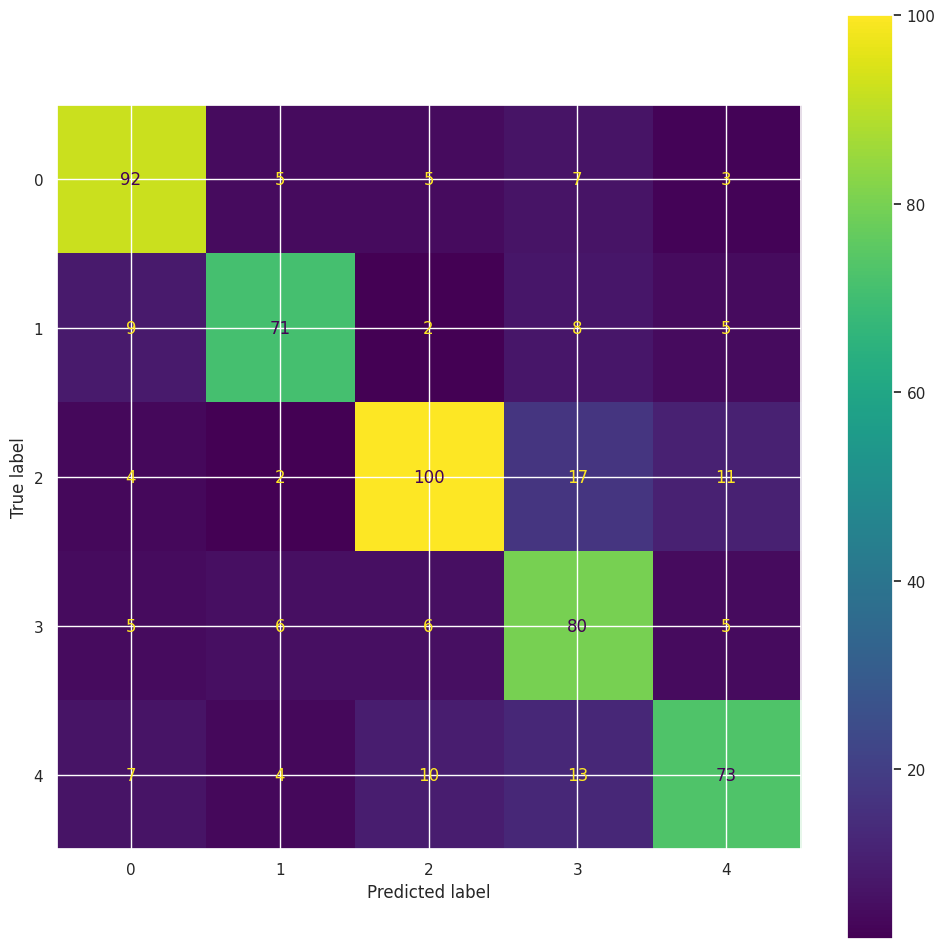

In [39]:
# plot confusion matrix of models prediction
from sklearn.metrics import ConfusionMatrixDisplay
predictions = model.predict(X_test)
print('Weighted F1-score is %.2f' %f1_score(y_test, convert_predictions(predictions), average='weighted'))
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay.from_predictions(y_test, convert_predictions(predictions),ax=ax)
plt.show()

## Resnet

In [40]:
from keras.applications import resnet

base_model = resnet.ResNet50(
    include_top=False,    # We do not include the top, because we just need the feature extraction layers
    weights='imagenet',
    input_shape=X_train.shape[1:],
    classes=y_train_enc.shape[1])

# We make the weight non-trainable to reduce the number of weights in the network
for layer in base_model.layers:
    layer.trainable = False

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [41]:
model = create_transfer_model(base_model)
model.summary()

Model: "sequential_38"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)                │ (None, 4, 4, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_38 (Flatten)                 │ (None, 32768)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_76 (Dense)                     │ (None, 128)                 │       4,194,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_77 (Dense)                     │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 27,782,789 (105.98 MB)

 Trainable params: 4,195,077 (16.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [42]:
history = model.fit(
      X_train, y_train_enc,
      verbose=1,
      epochs=20,
)

Epoch 1/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 24s 92ms/step - accuracy: 0.2388 - loss: 3.2796
Epoch 2/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.2507 - loss: 1.6103
Epoch 3/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.2534 - loss: 1.6028
Epoch 4/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.2548 - loss: 1.6016
Epoch 5/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.2585 - loss: 1.5988
Epoch 6/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.2621 - loss: 1.5968
Epoch 7/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.2538 - loss: 1.5978
Epoch 8/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.2486 - loss: 1.5987
Epoch 9/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.2561 - loss: 1.5978
Epoch 10/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.2420 - loss: 1.6016
Epoch 11/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.2524 - loss: 1.5973
Epoch 12/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy

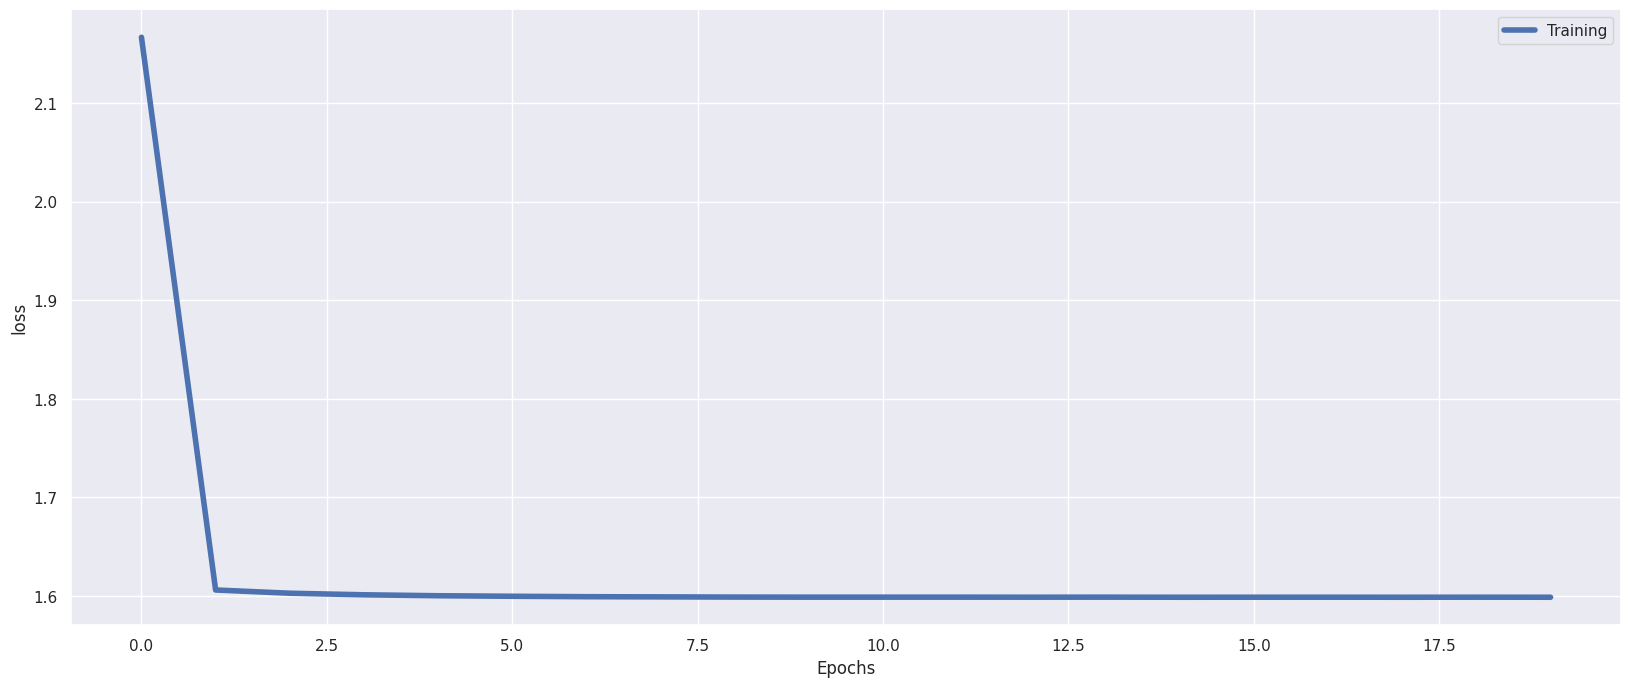

In [43]:
plot_history(history,plot_type='loss')

In [44]:
predictions = model.predict(X_test)
print('Weighted F1-score is %.2f' %f1_score(y_test, convert_predictions(predictions), average='weighted'))

18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 378ms/step
Weighted F1-score is 0.07


18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
Weighted F1-score is 0.07


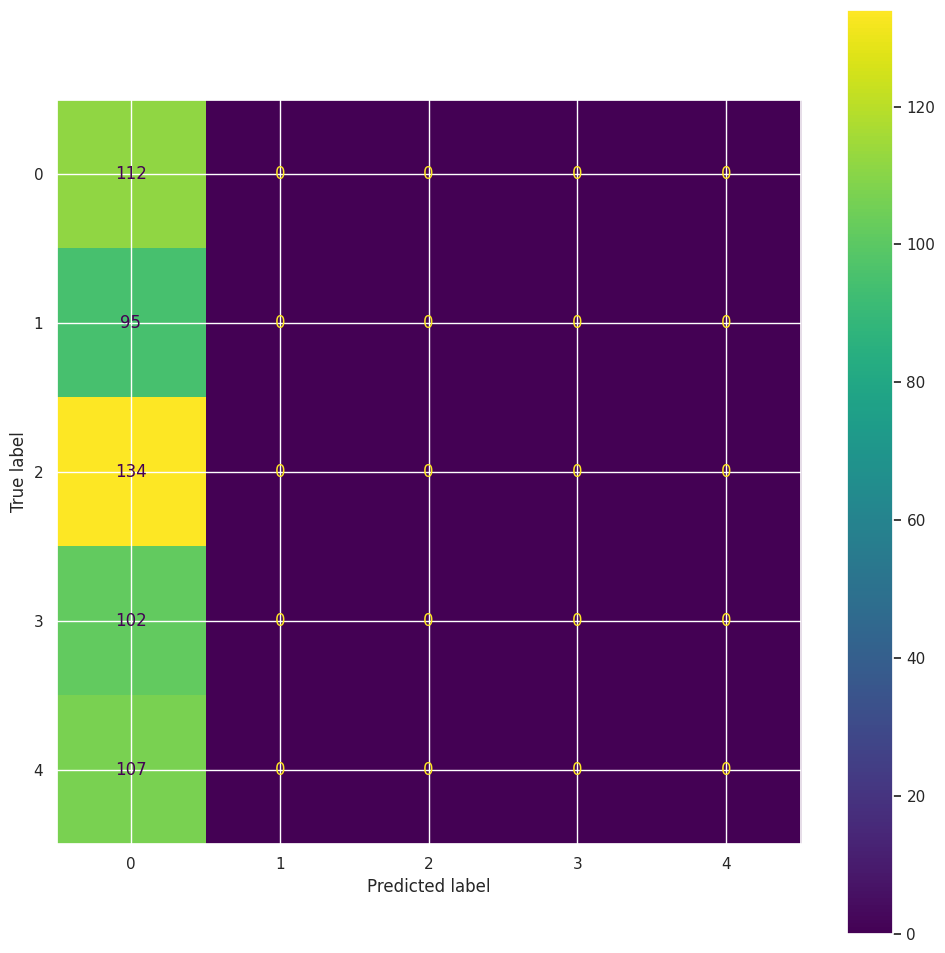

In [45]:
# plot confusion matrix of models prediction

predictions = model.predict(X_test)
print('Weighted F1-score is %.2f' %f1_score(y_test, convert_predictions(predictions), average='weighted'))
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay.from_predictions(y_test, convert_predictions(predictions),ax=ax)
plt.show()

Resnet is performing awfully!

The size of the receptive field in convolution layers has a significant impact on the performance and behavior of a neural network.

### **Increasing the receptive field size**
- **Effect**: The network captures more global or high-level features. This is because a larger receptive field allows the network to consider a broader spatial context at each layer.
- **Why**: Larger receptive fields aggregate information over a wider area, which is beneficial for tasks requiring understanding of global structures, such as object detection, scene recognition, or image classification. For example, identifying an object like a car requires the network to consider spatial relationships across a larger region.
- **Downside**: A larger receptive field increases computational cost and can lead to over-smoothing, where finer details are lost. It may also result in the model focusing less on local features, which are sometimes crucial for tasks like texture analysis.

### **Decreasing the receptive field size**
- **Effect**: The network focuses more on local, fine-grained details.
- **Why**: Smaller receptive fields are effective for capturing low-level features like edges, textures, or small patterns. They are particularly useful for tasks that require high-resolution details, such as semantic segmentation or super-resolution.
- **Downside**: If the receptive field is too small, the network may fail to capture the broader context or relationships between distant parts of the input, leading to suboptimal performance on tasks requiring a global understanding.

### **Balancing the receptive field**
In practice, the size of the receptive field is determined by a combination of kernel size, strides, and the depth of the network. Larger receptive fields can be achieved through stacking smaller convolution layers or using dilated convolutions, which efficiently increase the receptive field without increasing the kernel size.
